# The Calculus 1 Extra - 04. Calculus 1 Extra Practice with Integrals - Vol 2


<img src="./pics/cover.png" width=300> 

In [1]:
import setuptools

print("setuptools version:", setuptools.__version__)  # Should be < 70.0.0

import vpython as vp
from astropy import units as u
from astropy import constants as const
import sympy as sp
import numpy as np
from IPython.display import display, Math
import matplotlib.pyplot as plt
import sys
from pathlib import Path

print("All imports succeeded!")

setuptools version: 69.5.1


<IPython.core.display.Javascript object>

All imports succeeded!


In [2]:
!python --version

Python 3.13.13


In [3]:
pwd

'c:\\Users\\crodr\\Tutoriales\\Math\\Math_Tutor_DVD_Review\\Calculus_1_Extra_Practice\\04. Calculus 1 Extra Practice with Integrals - Vol 2'

In [4]:
C, n = sp.symbols("C, n", positive=True)
V, A, r, t, x, y, z, theta = sp.symbols("V, A, r, t, x, y, z, theta", real=True)
f, g, h = sp.symbols("f, g, h", cls=sp.Function)

In [5]:
# Add root folder to sys.path
sys.path.append(str(Path("../..").resolve()))

# Import your helper function directly
from helper_functions import fmt_vec, setup_math_axes


## Video 04. Calculating Volume with the Disk Method, Part 1


<img src="./pics/Fig04_01.png" width=600> 

Disk Method:

$$V = \int_a^b \pi \left[f(x)\right]^2 dx$$

### Exercise 1
Volume using disk method

$$f(x) = x^{3/2}  \quad \quad [0,1]$$

In [ ]:
# disk method
f = x ** (sp.Rational(3, 2))
V = sp.Integral(sp.pi * (f) ** 2, (x, 0, 1))
answer = V.doit()
display(Math(rf"f(x) = {sp.latex(f)}"))
display(Math(rf"{sp.latex(V)} = {sp.latex(answer)}"))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

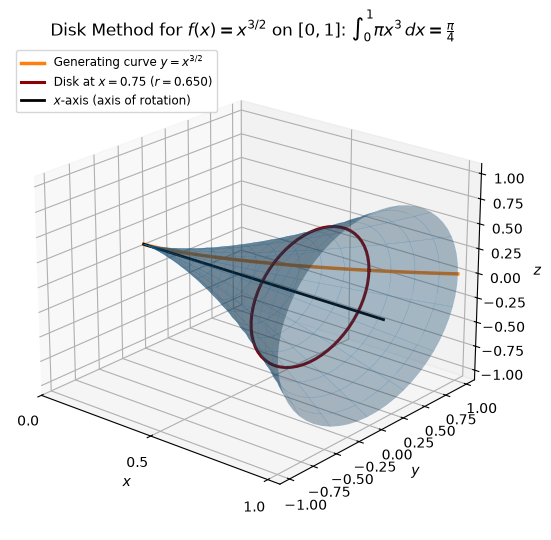

In [ ]:
# Symbolic radius f(x) = x^(3/2) on [0, 1]
x = sp.Symbol("x", real=True, nonnegative=True)
f_sym = x ** sp.Rational(3, 2)
f_num = sp.lambdify(x, f_sym, "numpy")

# Grid for solid of revolution around the x-axis: x in [0, 1], theta in [0, 2*pi]
x_vals = np.linspace(0.0, 1.0, 60)
theta_vals = np.linspace(0.0, 2.0 * np.pi, 60)
X, THETA = np.meshgrid(x_vals, theta_vals)

R = f_num(X)
Y = R * np.cos(THETA)
Z = R * np.sin(THETA)

fig = plt.figure(figsize=(8.5, 5.5))
ax = fig.add_subplot(111, projection="3d")

# Plot the revolved surface
ax.plot_surface(
    X,
    Y,
    Z,
    color="tab:blue",
    alpha=0.35,
    edgecolor="tab:blue",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)

# Highlight generating curve in the x-y plane (theta = 0, y = f(x), z = 0)
ax.plot(
    x_vals,
    f_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:orange",
    linewidth=2.5,
    label=r"Generating curve $y = x^{3/2}$",
)

# Highlight a representative circular disk slice at x = 0.75
x_disk = 0.75
r_disk = float(f_num(x_disk))
ax.plot(
    np.full_like(theta_vals, x_disk),
    r_disk * np.cos(theta_vals),
    r_disk * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
    label=rf"Disk at $x = {x_disk}$ ($r = {r_disk:.3f}$)",
)

# Axis of revolution (x-axis)
ax.plot(
    [0, 1.05],
    [0, 0],
    [0, 0],
    color="black",
    linewidth=2,
    label=r"$x$-axis (axis of rotation)",
)

ax.set_xlim(0, 1.05)
ax.set_ylim(-1.1, 1.1)
ax.set_zlim(-1.1, 1.1)
ax.set_xticks([0, 0.5, 1.0])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$z$")
ax.set_title(
    r"Disk Method for $f(x) = x^{3/2}$ on $[0, 1]$: $\int_{0}^{1} \pi x^3\,dx = \frac{\pi}{4}$"
)
ax.view_init(elev=22, azim=-50)
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

### Exercise 2
Volume using disk method

$$f(x) = -\frac{1}{x} \quad \quad [-3,-2]$$

In [ ]:
# disk method
f = -(1 / x)
V = sp.Integral(sp.pi * (f) ** 2, (x, -3, -2))
answer = V.doit()
display(Math(rf"f(x) = {sp.latex(f)}"))
display(Math(rf"{sp.latex(V)} = {sp.latex(answer)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

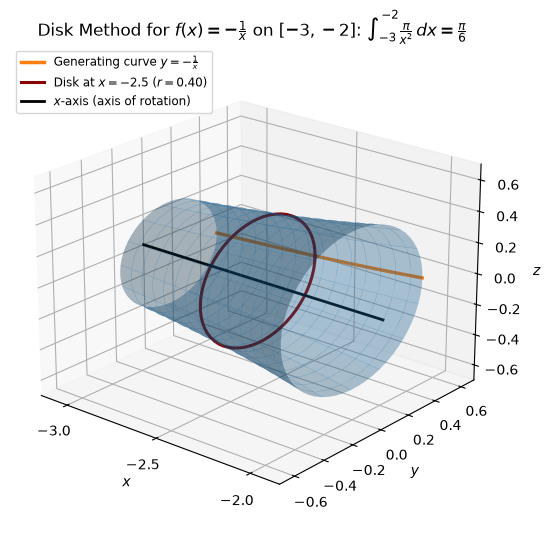

In [12]:
# Symbolic function f(x) = -1/x on [-3, -2]
x = sp.Symbol("x", real=True, negative=True)
f_sym = -1 / x
f_num = sp.lambdify(x, f_sym, "numpy")

# Grid for solid of revolution around the x-axis: x in [-3, -2], theta in [0, 2*pi]
x_vals = np.linspace(-3.0, -2.0, 60)
theta_vals = np.linspace(0.0, 2.0 * np.pi, 60)
X, THETA = np.meshgrid(x_vals, theta_vals)

# Disk radius is |f(x)| = 1/|x| = -1/x on [-3, -2]
R = np.abs(f_num(X))
Y = R * np.cos(THETA)
Z = R * np.sin(THETA)

fig = plt.figure(figsize=(8.5, 5.5))
ax = fig.add_subplot(111, projection="3d")

# Plot the revolved surface
ax.plot_surface(
    X,
    Y,
    Z,
    color="tab:blue",
    alpha=0.35,
    edgecolor="tab:blue",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)

# Highlight generating curve in the x-y plane (y = f(x) = -1/x, z = 0)
ax.plot(
    x_vals,
    f_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:orange",
    linewidth=2.5,
    label=r"Generating curve $y = -\frac{1}{x}$",
)

# Highlight a representative circular disk slice at x = -2.5
x_disk = -2.5
r_disk = abs(float(f_num(x_disk)))
ax.plot(
    np.full_like(theta_vals, x_disk),
    r_disk * np.cos(theta_vals),
    r_disk * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
    label=rf"Disk at $x = {x_disk}$ ($r = {r_disk:.2f}$)",
)

# Axis of revolution (x-axis)
ax.plot(
    [-3.15, -1.85],
    [0, 0],
    [0, 0],
    color="black",
    linewidth=2,
    label=r"$x$-axis (axis of rotation)",
)

ax.set_xlim(-3.15, -1.85)
ax.set_ylim(-0.7, 0.7)
ax.set_zlim(-0.7, 0.7)
ax.set_xticks([-3.0, -2.5, -2.0])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$z$")
ax.set_title(
    r"Disk Method for $f(x) = -\frac{1}{x}$ on $[-3, -2]$:"
    r" $\int_{-3}^{-2} \frac{\pi}{x^2}\,dx = \frac{\pi}{6}$"
)
ax.view_init(elev=22, azim=-50)
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

### Exercise 3
Volume using disk method

$$g(x) = \sqrt{\cos x} \quad \quad \left[0, \frac{\pi}{6}\right]$$

In [ ]:
# disk method
g = sp.sqrt(sp.cos(x))
V = sp.Integral(sp.pi * (g) ** 2, (x, 0, sp.pi / 6))
answer = V.doit()
display(Math(rf"g(x) = {sp.latex(g)}"))
display(Math(rf"{sp.latex(V)} = {sp.latex(answer)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

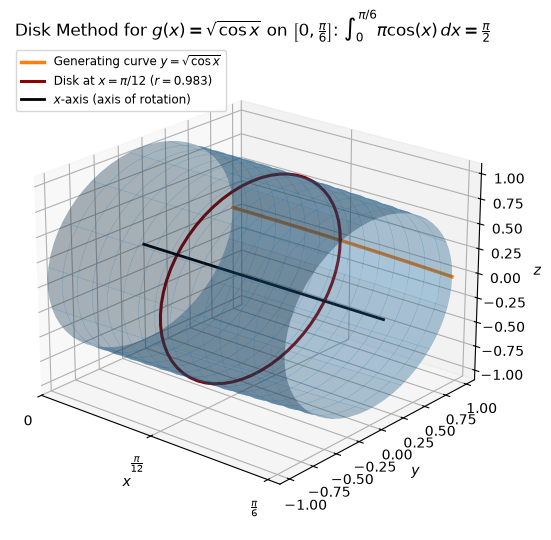

In [14]:
# Symbolic function g(x) = sqrt(cos(x)) on [0, pi/6]
x = sp.Symbol("x", real=True)
g_sym = sp.sqrt(sp.cos(x))
g_num = sp.lambdify(x, g_sym, "numpy")

# Grid for solid of revolution around the x-axis: x in [0, pi/6], theta in [0, 2*pi]
x_vals = np.linspace(0.0, np.pi / 6.0, 60)
theta_vals = np.linspace(0.0, 2.0 * np.pi, 60)
X, THETA = np.meshgrid(x_vals, theta_vals)

R = g_num(X)
Y = R * np.cos(THETA)
Z = R * np.sin(THETA)

fig = plt.figure(figsize=(8.5, 5.5))
ax = fig.add_subplot(111, projection="3d")

# Plot the revolved surface
ax.plot_surface(
    X,
    Y,
    Z,
    color="tab:blue",
    alpha=0.35,
    edgecolor="tab:blue",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)

# Highlight generating curve in the x-y plane (y = g(x) = sqrt(cos(x)), z = 0)
ax.plot(
    x_vals,
    g_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:orange",
    linewidth=2.5,
    label=r"Generating curve $y = \sqrt{\cos x}$",
)

# Highlight a representative circular disk slice at x = pi/12
x_disk = np.pi / 12.0
r_disk = float(g_num(x_disk))
ax.plot(
    np.full_like(theta_vals, x_disk),
    r_disk * np.cos(theta_vals),
    r_disk * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
    label=rf"Disk at $x = \pi/12$ ($r = {r_disk:.3f}$)",
)

# Axis of revolution (x-axis)
ax.plot(
    [0, np.pi / 6.0 * 1.05],
    [0, 0],
    [0, 0],
    color="black",
    linewidth=2,
    label=r"$x$-axis (axis of rotation)",
)

ax.set_xlim(0, np.pi / 6.0 * 1.05)
ax.set_ylim(-1.1, 1.1)
ax.set_zlim(-1.1, 1.1)
ax.set_xticks([0.0, np.pi / 12.0, np.pi / 6.0])
ax.set_xticklabels([r"$0$", r"$\frac{\pi}{12}$", r"$\frac{\pi}{6}$"])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$z$")
ax.set_title(
    r"Disk Method for $g(x) = \sqrt{\cos x}$ on $\left[0, \frac{\pi}{6}\right]$:"
    r" $\int_{0}^{\pi/6} \pi\cos(x)\,dx = \frac{\pi}{2}$"
)
ax.view_init(elev=22, azim=-50)
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()